# Airport network analysis with GraphFrames

This notebook runs in the classroom Jupyter container. Spark uses `local[*]`, so the whole job stays on that one machine. GraphFrames writes checkpoint files during connected components and label propagation, and those files have to stay on the same machine.

The two CSVs live in the repo folder `data/`. Inside the container that folder is `/opt/spark/lesson-data`.

Restart the kernel before the first cell if another notebook has already started Spark. The GraphFrames package is only picked up when the session starts. The first run downloads it, so the container needs internet once.


## 1. Setup

The cell below starts Spark, sets the checkpoint folder, and runs connected components on a test graph with three airports. GraphFrames is ready when A, B, and C share one component number.


In [ ]:
from pyspark.sql import SparkSession, functions as F

spark = (
    SparkSession.builder.appName("Airport Network Analysis")
    .master("local[*]")
    .config("spark.jars.packages", "graphframes:graphframes:0.8.2-spark3.2-s_2.12")
    .config("spark.driver.memory", "2g")
    .getOrCreate()
)
spark.sparkContext.setCheckpointDir("/tmp/graphframes_airport_checkpoints")
spark.conf.set("spark.sql.shuffle.partitions", "8")

from graphframes import GraphFrame


def display(df):
    df.show(20, truncate=False)


AIRPORTS = "/opt/spark/lesson-data/airports.csv"
FLIGHTS = "/opt/spark/lesson-data/T_ONTIME_REPORTING.csv"

test_graph = GraphFrame(
    spark.createDataFrame([("A",), ("B",), ("C",)], ["id"]),
    spark.createDataFrame([("A", "B"), ("B", "C")], ["src", "dst"]),
)
display(test_graph.connectedComponents())


## 2. Load the two files

`header` uses the first row as column names. `inferSchema` reads a sample and assigns the column types. Both frames are cached because the later sections scan them more than once.

### Columns used from `airports.csv`

| Column | Role in the graph |
| --- | --- |
| `iata` | Vertex id |
| `name` | Airport name |
| `city`, `state` | Labels on the tables |
| `latitude`, `longitude` | Map coordinates |

### Columns used from `T_ONTIME_REPORTING.csv`

| Column | Role in the graph |
| --- | --- |
| `ORIGIN`, `DEST` | IATA codes. These become `src` and `dst` |
| `ORIGIN_AIRPORT_ID` | Numeric Bureau of Transportation Statistics id |
| `ORIGIN_CITY_NAME` | City label |
| `DEP_DELAY`, `ARR_DELAY` | Delay in minutes. Blank when the delay was not recorded |
| `OP_CARRIER_FL_NUM` | Flight number. This extract has no airline code |


In [ ]:
airports_df = (
    spark.read.option("header", True).option("inferSchema", True).csv(AIRPORTS).cache()
)
flights_df = (
    spark.read.option("header", True).option("inferSchema", True).csv(FLIGHTS).cache()
)

print(f"{airports_df.count():,} airports from {AIRPORTS}")
airports_df.printSchema()
display(airports_df.limit(5))

print(f"{flights_df.count():,} flights from {FLIGHTS}")
flights_df.printSchema()
display(flights_df.limit(5))


## 3. Explore routes before building the graph

A vertex is an airport that appears as an origin or a destination. An edge is a distinct `(ORIGIN, DEST)` pair. The same flight number can belong to different airlines, and this extract does not include a carrier column, so the useful counts are cities and routes.


In [ ]:
print(f"Origin airports: {flights_df.select('ORIGIN').distinct().count():,}")
print(f"Destination airports: {flights_df.select('DEST').distinct().count():,}")

print("Busiest origins")
display(
    flights_df.groupBy("ORIGIN", "ORIGIN_CITY_NAME")
    .count()
    .orderBy(F.desc("count"))
    .limit(10)
)

print("Busiest routes")
display(
    flights_df.groupBy("ORIGIN", "DEST")
    .agg(
        F.count("*").alias("flights"),
        F.round(F.avg(F.col("DEP_DELAY").cast("double")), 1).alias("avg_dep_delay"),
        F.round(F.avg(F.col("ARR_DELAY").cast("double")), 1).alias("avg_arr_delay"),
    )
    .orderBy(F.desc("flights"))
    .limit(10)
)


## 4. The same questions in Spark SQL

The DataFrame aggregations above are registered as views so the next queries can use SQL. `DEP_DELAY` is cast to double because a blank delay is null, and `AVG` skips nulls.

The state count reads the full airports file, including small fields with no airline flight in this extract.


In [ ]:
airports_df.createOrReplaceTempView("airports")
flights_df.createOrReplaceTempView("flights")

display(spark.sql("""
    SELECT
        ORIGIN AS src,
        DEST AS dst,
        COUNT(*) AS flights,
        ROUND(AVG(CAST(DEP_DELAY AS DOUBLE)), 1) AS avg_dep_delay
    FROM flights
    GROUP BY ORIGIN, DEST
    ORDER BY flights DESC
    LIMIT 10
"""))

display(spark.sql("""
    SELECT state, COUNT(*) AS airports
    FROM airports
    GROUP BY state
    ORDER BY airports DESC
    LIMIT 10
"""))


## 5. Vertices

The vertex id is the IATA code, stored as a string. The airports file also contains fields that never appear in this flight extract. Those fields stay out of the graph so degree and PageRank describe the flown network.

Flight airports missing from the airports table stay in the graph. The IATA code fills in for the missing name.


In [ ]:
endpoints = (
    flights_df.select(F.col("ORIGIN").cast("string").alias("id"))
    .union(flights_df.select(F.col("DEST").cast("string").alias("id")))
    .distinct()
)

vertices = (
    endpoints.join(airports_df, endpoints.id == F.col("iata").cast("string"), "left")
    .select(
        endpoints.id.alias("id"),
        F.coalesce(F.col("name"), endpoints.id).alias("airport_name"),
        F.col("city"),
        F.col("state"),
        F.col("latitude").cast("double").alias("latitude"),
        F.col("longitude").cast("double").alias("longitude"),
    )
    .cache()
)

print(f"Vertices: {vertices.count():,}")
display(vertices.orderBy("id").limit(5))

coords = (
    vertices.filter(F.col("latitude").isNotNull() & F.col("longitude").isNotNull())
    .select("id", "latitude", "longitude")
    .toPandas()
)
airport_coords = {
    row.id: (row.latitude, row.longitude) for row in coords.itertuples(index=False)
}
print(f"Airports with coordinates: {len(airport_coords):,}")


## 6. Edges

Each edge is one directed route. `flight_count` is the number of flights on that route. The delay columns are averages over flights that recorded a delay.

GraphFrames requires the column names `src` and `dst`.


In [ ]:
edges = (
    flights_df.select(
        F.col("ORIGIN").cast("string").alias("src"),
        F.col("DEST").cast("string").alias("dst"),
        F.col("DEP_DELAY").cast("double").alias("dep_delay"),
        F.col("ARR_DELAY").cast("double").alias("arr_delay"),
    )
    .groupBy("src", "dst")
    .agg(
        F.count("*").alias("flight_count"),
        F.round(F.avg("dep_delay"), 2).alias("avg_dep_delay"),
        F.round(F.avg("arr_delay"), 2).alias("avg_arr_delay"),
    )
    .cache()
)

print(f"Edges: {edges.count():,}")
display(edges.orderBy(F.desc("flight_count")).limit(5))

display(spark.sql("""
    SELECT
        ORIGIN AS src,
        DEST AS dst,
        COUNT(*) AS flight_count,
        ROUND(AVG(CAST(DEP_DELAY AS DOUBLE)), 2) AS avg_dep_delay
    FROM flights
    GROUP BY ORIGIN, DEST
    ORDER BY flight_count DESC
    LIMIT 5
"""))


## 7. Build the GraphFrame

`cache()` keeps the vertex and edge frames for the algorithms that follow. Degree counts incident routes. It is the sum of in-degree and out-degree, so a route flown in both directions contributes two.


In [ ]:
graph = GraphFrame(vertices, edges)
print(f"Graph vertices: {graph.vertices.count():,}")
print(f"Graph edges: {graph.edges.count():,}")


## 8. Map the busiest routes

The axes cover the continental United States. Routes in Alaska, Hawaii, and the territories are in the edge table and fall outside this window. Line width follows `flight_count`. The labels are the eight airports with the most plotted flights.


In [ ]:
import matplotlib.pyplot as plt

top_routes = edges.orderBy(F.desc("flight_count")).limit(50).toPandas()
print(f"Routes loaded for the map: {len(top_routes)}")


def plot_top_routes():
    fig, ax = plt.subplots(figsize=(15, 10))
    plotted = {}
    for edge in top_routes.itertuples(index=False):
        if edge.src not in airport_coords or edge.dst not in airport_coords:
            continue
        src_lat, src_lon = airport_coords[edge.src]
        dst_lat, dst_lon = airport_coords[edge.dst]
        width = max(0.5, min(5, edge.flight_count / 500))
        ax.plot([src_lon, dst_lon], [src_lat, dst_lat], color="steelblue", alpha=0.45, linewidth=width)
        plotted[edge.src] = (src_lat, src_lon)
        plotted[edge.dst] = (dst_lat, dst_lon)

    traffic = {}
    for airport_id, (lat, lon) in plotted.items():
        ax.scatter(lon, lat, s=40, c="firebrick", alpha=0.9, edgecolors="black", linewidths=0.4, zorder=3)
        traffic[airport_id] = top_routes.loc[
            (top_routes["src"] == airport_id) | (top_routes["dst"] == airport_id),
            "flight_count",
        ].sum()

    for airport_id, _ in sorted(traffic.items(), key=lambda item: item[1], reverse=True)[:8]:
        lat, lon = plotted[airport_id]
        ax.annotate(airport_id, (lon, lat), xytext=(4, 4), textcoords="offset points", fontsize=9, fontweight="bold")

    ax.set_title("Top 50 routes, continental window")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.set_xlim(-125, -65)
    ax.set_ylim(25, 50)
    ax.grid(True, alpha=0.3)
    fig.tight_layout()
    plt.show()


plot_top_routes()


## 9. All airports, with the main hubs marked

Gray points are every airport in `airports.csv`. Red points are the 15 vertices with the highest degree in the flight graph. The window is again the continental United States, and the cell prints how many airports fall outside it.


In [ ]:
import matplotlib.pyplot as plt

all_airports = (
    airports_df.filter(F.col("latitude").isNotNull() & F.col("longitude").isNotNull())
    .select(
        F.col("iata").cast("string").alias("id"),
        F.col("latitude").cast("double").alias("latitude"),
        F.col("longitude").cast("double").alias("longitude"),
    )
    .toPandas()
)
hubs = (
    graph.degrees.join(vertices, "id")
    .select("id", "latitude", "longitude", "degree")
    .filter(F.col("latitude").isNotNull())
    .orderBy(F.desc("degree"))
    .limit(15)
    .toPandas()
)

outside = all_airports[
    (all_airports["longitude"] < -130)
    | (all_airports["longitude"] > -60)
    | (all_airports["latitude"] < 20)
    | (all_airports["latitude"] > 55)
]
print(f"Airports outside the continental window: {len(outside):,}")


def plot_airports():
    fig, ax = plt.subplots(figsize=(15, 10))
    ax.scatter(
        all_airports["longitude"],
        all_airports["latitude"],
        s=12,
        c="lightsteelblue",
        alpha=0.7,
        linewidths=0,
    )
    ax.scatter(
        hubs["longitude"],
        hubs["latitude"],
        s=80,
        c="firebrick",
        alpha=0.9,
        edgecolors="black",
        linewidths=0.6,
        zorder=3,
    )
    for hub in hubs.itertuples(index=False):
        ax.annotate(
            hub.id,
            (hub.longitude, hub.latitude),
            xytext=(4, 4),
            textcoords="offset points",
            fontsize=8,
            fontweight="bold",
        )
    ax.set_title("Airports in the file, top 15 hubs by degree")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.set_xlim(-130, -60)
    ax.set_ylim(20, 55)
    ax.grid(True, alpha=0.3)
    fig.tight_layout()
    plt.show()


plot_airports()


## 10. Degree

`degrees` counts routes, in each direction. `inDegrees` counts incoming routes and `outDegrees` counts outgoing routes. An airport with a nonstop to 100 other airports has degree near 200 when those routes are flown both ways.

The SQL query under the degree tables counts flights instead of routes. A hub can lead one list and not the other.


In [ ]:
in_degrees = graph.inDegrees
out_degrees = graph.outDegrees
degrees = graph.degrees.cache()
degrees.count()

print("Highest degree")
display(
    degrees.join(vertices, "id")
    .select("id", "airport_name", "city", "state", "degree")
    .orderBy(F.desc("degree"))
    .limit(10)
)

print("Highest in-degree")
display(
    in_degrees.join(vertices, "id")
    .select("id", "airport_name", "city", "state", "inDegree")
    .orderBy(F.desc("inDegree"))
    .limit(10)
)

print("Highest out-degree")
display(
    out_degrees.join(vertices, "id")
    .select("id", "airport_name", "city", "state", "outDegree")
    .orderBy(F.desc("outDegree"))
    .limit(10)
)


In [ ]:
print("Departing flights by airport")
display(spark.sql("""
    SELECT
        a.iata,
        a.name,
        a.city,
        a.state,
        COUNT(*) AS departing_flights
    FROM flights f
    JOIN airports a ON f.ORIGIN = a.iata
    GROUP BY a.iata, a.name, a.city, a.state
    ORDER BY departing_flights DESC
    LIMIT 10
"""))


## 11. Shortest paths

`shortestPaths` reports hop count. A nonstop route is 1 hop. The landmark is the vertex id, which is the IATA code. Atlanta is `ATL`. The numeric id `10397` is `ORIGIN_AIRPORT_ID` for the same airport, and it is a different column.


In [ ]:
display(
    flights_df.filter(F.col("ORIGIN") == "ATL")
    .select("ORIGIN", "ORIGIN_AIRPORT_ID", "ORIGIN_CITY_NAME")
    .distinct()
)

HUB = "ATL"
paths = (
    graph.shortestPaths(landmarks=[HUB])
    .select("id", "distances")
    .join(vertices, "id")
    .select(
        "id",
        "airport_name",
        "city",
        "state",
        F.col("distances").getItem(HUB).alias("hops_from_atl"),
    )
    .cache()
)

print("Airports farthest from ATL, in hops")
display(paths.orderBy(F.desc_nulls_last("hops_from_atl")).limit(10))


def hops_between(start_id, end_id):
    """Hop count from start_id to end_id. The landmark is the destination."""
    row = (
        graph.shortestPaths(landmarks=[end_id])
        .select("id", "distances")
        .filter(F.col("id") == start_id)
        .select(F.col("distances").getItem(end_id).alias("hops"))
        .collect()
    )
    if not row or row[0]["hops"] is None:
        return f"No path from {start_id} to {end_id}"
    return f"{start_id} to {end_id}: {int(row[0]['hops'])} hops"


print(hops_between("ATL", "SEA"))
print(hops_between("ATL", "LAX"))


## 12. Motifs

A motif is a structural pattern written as a path. The triangle query finds directed cycles of three airports: `a → b → c → a`. The same cycle is returned once for each starting airport.

The second query finds pairs with a flight in each direction. The filter keeps each unordered pair once.


In [ ]:
triangles = (
    graph.find("(a)-[ab]->(b); (b)-[bc]->(c); (c)-[ca]->(a)")
    .select(
        F.col("a.id").alias("a"),
        F.col("b.id").alias("b"),
        F.col("c.id").alias("c"),
        F.col("a.airport_name").alias("a_name"),
        F.col("b.airport_name").alias("b_name"),
        F.col("c.airport_name").alias("c_name"),
    )
    .cache()
)
print(f"Directed triangle embeddings: {triangles.count():,}")
display(triangles.limit(10))

both_ways = (
    graph.find("(a)-[]->(b); (b)-[]->(a)")
    .filter(F.col("a.id") < F.col("b.id"))
    .select(
        F.col("a.id").alias("a"),
        F.col("b.id").alias("b"),
        F.col("a.airport_name").alias("a_name"),
        F.col("b.airport_name").alias("b_name"),
    )
    .distinct()
    .cache()
)
print(f"Airport pairs with flights both ways: {both_ways.count():,}")
display(both_ways.orderBy("a", "b").limit(10))


### A busy triangle

This is the same cycle as the cell above. The edge names `ab`, `bc`, and `ca` are what make `flight_count` available. Each leg must have at least 100 flights. The filter `a.id < b.id` and `a.id < c.id` lists each cycle once, starting at the airport whose code comes first.


In [16]:
busy_triangles = (
    graph.find("(a)-[ab]->(b); (b)-[bc]->(c); (c)-[ca]->(a)")
    .filter((F.col("a.id") < F.col("b.id")) & (F.col("a.id") < F.col("c.id")))
    .filter(
        (F.col("ab.flight_count") >= 100)
        & (F.col("bc.flight_count") >= 100)
        & (F.col("ca.flight_count") >= 100)
    )
    .select(
        F.col("a.id").alias("a"),
        F.col("b.id").alias("b"),
        F.col("c.id").alias("c"),
        F.col("ab.flight_count").alias("ab_flights"),
        F.col("bc.flight_count").alias("bc_flights"),
        F.col("ca.flight_count").alias("ca_flights"),
    )
)
print(f"Busy triangles: {busy_triangles.count():,}")
display(busy_triangles.orderBy(F.desc("ab_flights")).limit(10))


Busy triangles: 7,306
+---+---+---+----------+----------+----------+
|a  |b  |c  |ab_flights|bc_flights|ca_flights|
+---+---+---+----------+----------+----------+
|HNL|OGG|SEA|985       |154       |278       |
|HNL|OGG|LIH|985       |124       |718       |
|HNL|OGG|SFO|985       |110       |199       |
|HNL|OGG|KOA|985       |127       |677       |
|HNL|OGG|LAX|985       |137       |427       |
|LGA|ORD|MIA|919       |409       |572       |
|LGA|ORD|TPA|919       |277       |204       |
|LGA|ORD|MCI|919       |263       |140       |
|LGA|ORD|STL|919       |150       |220       |
|LGA|ORD|MSP|919       |460       |200       |
+---+---+---+----------+----------+----------+



### A flight with no return

`(a)-[ab]->(b); !(b)-[]->(a)` keeps a flight from `a` to `b` only when the return flight is missing. The `!` is the part that rejects the return. `ab` is named so the table can show `flight_count`. The return edge uses `[]` because the pattern only needs to know that it is absent.


In [17]:
one_way = (
    graph.find("(a)-[ab]->(b); !(b)-[]->(a)")
    .select(
        F.col("a.id").alias("src"),
        F.col("b.id").alias("dst"),
        F.col("a.airport_name").alias("src_name"),
        F.col("b.airport_name").alias("dst_name"),
        F.col("ab.flight_count").alias("flights"),
    )
)
print(f"One-way routes: {one_way.count():,}")
display(one_way.orderBy(F.desc("flights")).limit(10))


One-way routes: 9
+---+---+--------------------------------+----------------------------+-------+
|src|dst|src_name                        |dst_name                    |flights|
+---+---+--------------------------------+----------------------------+-------+
|CLE|PIT|Cleveland-Hopkins Intl          |Pittsburgh International    |26     |
|BOS|STT|Gen Edw L Logan Intl            |Cyril E. King               |18     |
|SAV|AVL|Savannah International          |Asheville Regional          |1      |
|PHX|MDT|Phoenix Sky Harbor International|Harrisburg Intl             |1      |
|PHL|MSN|Philadelphia Intl               |Dane County Regional        |1      |
|BIS|DIK|Bismarck Municipal              |Dickinson Municipal         |1      |
|MSP|RIC|Minneapolis-St Paul Intl        |Richmond International      |1      |
|GRR|IAH|Kent County International       |George Bush Intercontinental|1      |
|XNA|IAH|Northwest Arkansas Regional     |George Bush Intercontinental|1      |
+---+---+-------------

### One stop from Atlanta

`(a)-[ab]->(b); (b)-[bc]->(c)` is two flights in a row. `a` is Atlanta, `b` is the stop, and `c` is the destination. The edge names `ab` and `bc` supply the flight counts for each leg. A nonstop flight from Atlanta to `c` may also exist. This pattern does not remove it.


In [18]:
one_stop = (
    graph.find("(a)-[ab]->(b); (b)-[bc]->(c)")
    .filter(F.col("a.id") == "ATL")
    .filter(F.col("c.id") != "ATL")
    .select(
        F.col("b.id").alias("stop"),
        F.col("c.id").alias("destination"),
        F.col("ab.flight_count").alias("atl_to_stop"),
        F.col("bc.flight_count").alias("stop_to_destination"),
    )
)
display(one_stop.orderBy(F.desc("atl_to_stop")).limit(10))


+----+-----------+-----------+-------------------+
|stop|destination|atl_to_stop|stop_to_destination|
+----+-----------+-----------+-------------------+
|MCO |AVL        |690        |11                 |
|MCO |BTV        |690        |18                 |
|MCO |RIC        |690        |69                 |
|MCO |MDT        |690        |13                 |
|MCO |PWM        |690        |25                 |
|MCO |BUF        |690        |173                |
|MCO |ALB        |690        |111                |
|MCO |MEM        |690        |66                 |
|MCO |GRR        |690        |60                 |
|MCO |ABQ        |690        |1                  |
+----+-----------+-----------+-------------------+



## 13. PageRank

PageRank scores airports by the routes that point at them. Every route counts as one edge. `flight_count` remains an attribute of that edge. GraphFrames reads an edge column named `weight` when it is present. This graph leaves that column out, so PageRank follows the route structure.

The comparison table puts route degree, departing flights, and PageRank on the same rows.


In [19]:
pagerank_results = graph.pageRank(resetProbability=0.15, maxIter=10)
ranks = pagerank_results.vertices.select("id", "pagerank").cache()
ranks.count()

print("Highest PageRank")
display(
    ranks.join(vertices, "id")
    .select("id", "airport_name", "city", "state", F.round("pagerank", 4).alias("pagerank"))
    .orderBy(F.desc("pagerank"))
    .limit(10)
)

departures = edges.groupBy(F.col("src").alias("id")).agg(
    F.sum("flight_count").alias("departing_flights")
)
comparison = (
    degrees.join(departures, "id", "left")
    .join(ranks, "id")
    .join(vertices.select("id", "airport_name", "city", "state"), "id")
    .select(
        "id",
        "airport_name",
        "city",
        "state",
        "degree",
        F.coalesce(F.col("departing_flights"), F.lit(0)).alias("departing_flights"),
        F.round("pagerank", 4).alias("pagerank"),
    )
    .orderBy(F.desc("pagerank"))
)
print("Degree, departing flights, and PageRank")
display(comparison.limit(15))


/opt/spark/python/pyspark/sql/dataframe.py:148: UserWarning: DataFrame.sql_ctx is an internal property, and will be removed in future releases. Use DataFrame.sparkSession instead.
  warnings.warn(


Highest PageRank
+---+---------------------------------+-----------------+-----+--------+
|id |airport_name                     |city             |state|pagerank|
+---+---------------------------------+-----------------+-----+--------+
|DFW|Dallas-Fort Worth International  |Dallas-Fort Worth|TX   |11.9672 |
|DEN|Denver Intl                      |Denver           |CO   |10.9481 |
|ORD|Chicago O'Hare International     |Chicago          |IL   |8.4805  |
|ATL|William B Hartsfield-Atlanta Intl|Atlanta          |GA   |6.8985  |
|LAS|McCarran International           |Las Vegas        |NV   |6.3962  |
|CLT|Charlotte/Douglas International  |Charlotte        |NC   |6.2468  |
|MSP|Minneapolis-St Paul Intl         |Minneapolis      |MN   |6.0064  |
|PHX|Phoenix Sky Harbor International |Phoenix          |AZ   |5.3582  |
|DTW|Detroit Metropolitan-Wayne County|Detroit          |MI   |4.7252  |
|SLC|Salt Lake City Intl              |Salt Lake City   |UT   |4.6959  |
+---+-----------------------------

## 14. Connected components and communities

`connectedComponents` groups airports that can reach each other when direction is ignored. `labelPropagation` assigns a community label. On a dense route graph the result is often one large community plus a few small ones. Labels can change between runs.

Both algorithms use the checkpoint directory created in the setup cell.


In [20]:
components = graph.connectedComponents().select("id", "component")
component_sizes = components.groupBy("component").count().orderBy(F.desc("count"))
print("Connected components")
display(component_sizes)

communities = graph.labelPropagation(maxIter=5).select("id", "label")
community_sizes = communities.groupBy("label").count().orderBy(F.desc("count"))
print(f"Communities: {community_sizes.count():,}")
display(community_sizes.limit(10))


Connected components
+---------+-----+
|component|count|
+---------+-----+
|0        |329  |
+---------+-----+

Communities: 4
+-----------+-----+
|label      |count|
+-----------+-----+
|8589934613 |321  |
|41         |4    |
|42949672989|2    |
|17179869214|2    |
+-----------+-----+



## 15. Degree and PageRank bars

The bars use the IATA code. Degree is on the left and PageRank is on the right. The two rankings can differ because PageRank follows who points at an airport, and degree only counts routes.


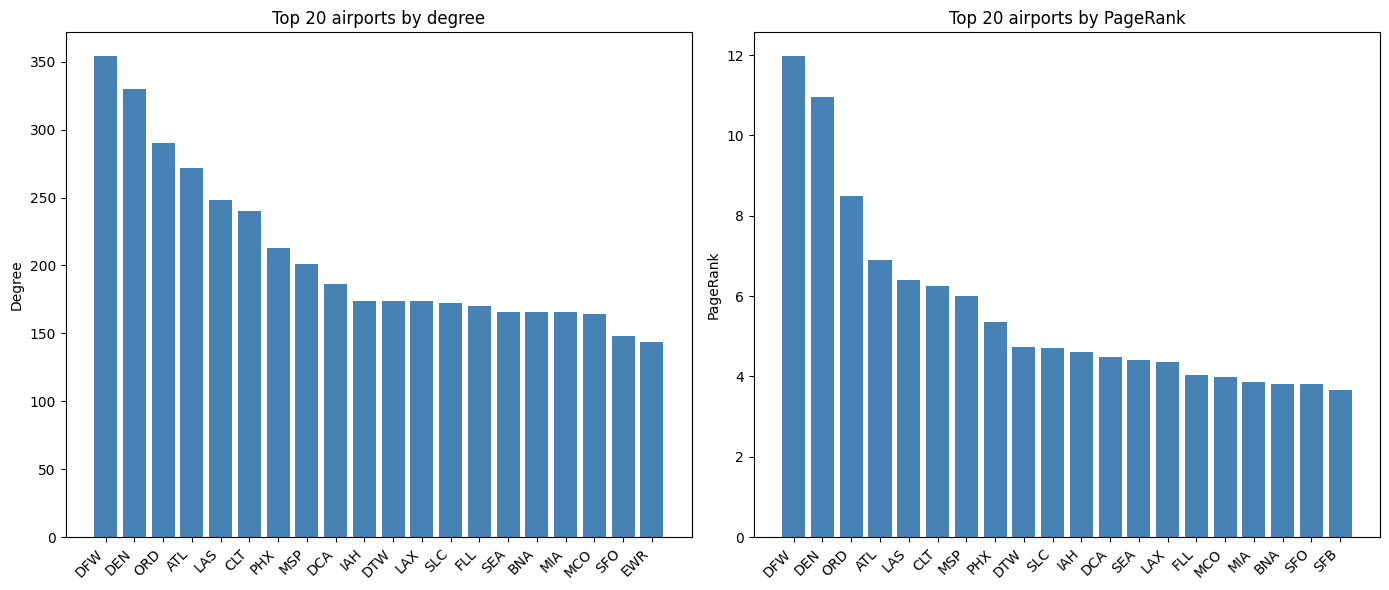

In [21]:
import matplotlib.pyplot as plt

degree_top = (
    degrees.join(vertices, "id")
    .select("id", "degree")
    .orderBy(F.desc("degree"))
    .limit(20)
    .toPandas()
)
pagerank_top = (
    ranks.join(vertices, "id")
    .select("id", "pagerank")
    .orderBy(F.desc("pagerank"))
    .limit(20)
    .toPandas()
)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].bar(range(len(degree_top)), degree_top["degree"], color="steelblue")
axes[0].set_xticks(range(len(degree_top)))
axes[0].set_xticklabels(degree_top["id"], rotation=45, ha="right")
axes[0].set_title("Top 20 airports by degree")
axes[0].set_ylabel("Degree")

axes[1].bar(range(len(pagerank_top)), pagerank_top["pagerank"], color="steelblue")
axes[1].set_xticks(range(len(pagerank_top)))
axes[1].set_xticklabels(pagerank_top["id"], rotation=45, ha="right")
axes[1].set_title("Top 20 airports by PageRank")
axes[1].set_ylabel("PageRank")

fig.tight_layout()
plt.show()


## 16. Hubs by region

These lists use degree inside three groups of states. An airport with a null state is one of the flight airports missing from the airports table, so it does not appear here.


In [22]:
print("Airports in the flight graph, by state")
display(vertices.groupBy("state").count().orderBy(F.desc("count")).limit(10))

northeast = ["NY", "NJ", "PA", "MA", "CT", "RI", "VT", "NH", "ME"]
southwest = ["TX", "AZ", "NM", "NV"]
west_coast = ["CA", "WA", "OR"]

ranked = degrees.join(vertices, "id").select("id", "airport_name", "city", "state", "degree")

print("Northeast")
display(ranked.filter(F.col("state").isin(northeast)).orderBy(F.desc("degree")).limit(5))

print("Southwest")
display(ranked.filter(F.col("state").isin(southwest)).orderBy(F.desc("degree")).limit(5))

print("West coast")
display(ranked.filter(F.col("state").isin(west_coast)).orderBy(F.desc("degree")).limit(5))


Airports in the flight graph, by state
+-----+-----+
|state|count|
+-----+-----+
|TX   |25   |
|CA   |22   |
|FL   |18   |
|AK   |16   |
|MI   |13   |
|NY   |11   |
|IL   |10   |
|WY   |9    |
|CO   |9    |
|MN   |8    |
+-----+-----+

Northeast
+---+--------------------+------------+-----+------+
|id |airport_name        |city        |state|degree|
+---+--------------------+------------+-----+------+
|EWR|Newark Intl         |Newark      |NJ   |144   |
|LGA|LaGuardia           |New York    |NY   |130   |
|BOS|Gen Edw L Logan Intl|Boston      |MA   |125   |
|JFK|John F Kennedy Intl |New York    |NY   |116   |
|PHL|Philadelphia Intl   |Philadelphia|PA   |111   |
+---+--------------------+------------+-----+------+

Southwest
+---+--------------------------------+-----------------+-----+------+
|id |airport_name                    |city             |state|degree|
+---+--------------------------------+-----------------+-----+------+
|DFW|Dallas-Fort Worth International |Dallas-Fort Worth|

26/11/04 22:19:20 WARN JavaUtils: Attempt to delete using native Unix OS command failed for path = /tmp/blockmgr-6617dca7-685f-47ee-96b4-52f6b3f1973d. Falling back to Java IO way
java.io.IOException: Failed to delete: /tmp/blockmgr-6617dca7-685f-47ee-96b4-52f6b3f1973d
	at org.apache.spark.network.util.JavaUtils.deleteRecursivelyUsingUnixNative(JavaUtils.java:171)
	at org.apache.spark.network.util.JavaUtils.deleteRecursively(JavaUtils.java:110)
	at org.apache.spark.network.util.JavaUtils.deleteRecursively(JavaUtils.java:91)
	at org.apache.spark.util.Utils$.deleteRecursively(Utils.scala:1206)
	at org.apache.spark.storage.DiskBlockManager.$anonfun$doStop$1(DiskBlockManager.scala:374)
	at org.apache.spark.storage.DiskBlockManager.$anonfun$doStop$1$adapted(DiskBlockManager.scala:370)
	at scala.collection.IndexedSeqOptimized.foreach(IndexedSeqOptimized.scala:36)
	at scala.collection.IndexedSeqOptimized.foreach$(IndexedSeqOptimized.scala:33)
	at scala.collection.mutable.ArrayOps$ofRef.foreach

----------------------------------------
Exception occurred during processing of request from ('127.0.0.1', 54056)
Traceback (most recent call last):
  File "/usr/local/lib/python3.10/socketserver.py", line 316, in _handle_request_noblock
    self.process_request(request, client_address)
  File "/usr/local/lib/python3.10/socketserver.py", line 347, in process_request
    self.finish_request(request, client_address)
  File "/usr/local/lib/python3.10/socketserver.py", line 360, in finish_request
    self.RequestHandlerClass(request, client_address, self)
  File "/usr/local/lib/python3.10/socketserver.py", line 747, in __init__
    self.handle()
  File "/opt/spark/python/pyspark/accumulators.py", line 281, in handle
    poll(accum_updates)
  File "/opt/spark/python/pyspark/accumulators.py", line 253, in poll
    if func():
  File "/opt/spark/python/pyspark/accumulators.py", line 257, in accum_updates
    num_updates = read_int(self.rfile)
  File "/opt/spark/python/pyspark/serializers.py",

## 17. Summary

The totals below are taken from the cached edge frame. Leave this Spark session running if you want to keep querying `graph`, `vertices`, or `edges`.


In [ ]:
totals = edges.agg(
    F.sum("flight_count").alias("total_flights"),
    F.avg("flight_count").alias("avg_flights_per_route"),
).collect()[0]

print(f"Airports in the flight graph: {vertices.count():,}")
print(f"Routes: {edges.count():,}")
print(f"Flights: {totals['total_flights']:,.0f}")
print(f"Average flights per route: {totals['avg_flights_per_route']:.2f}")
print(f"Airports with coordinates: {vertices.filter(F.col('latitude').isNotNull()).count():,}")
print("Spark session is still running.")
